<a href="https://colab.research.google.com/github/laoneya31/IAT360-Group-18/blob/main/notebooks/Jasper_Annotation_ImageSize_Augmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1><b>Annotation Review, Image Size and Augmentation</b></h1></center>
<center>IAT 360 Group 18 (Jasper)</center>

**Tasks:** review annotations, class distribution chart and split percentages, tune `imgsz`, run the bonus augmentation comparison.

# 1. Environment

Use a GPU runtime: **Runtime > Change runtime type > T4 GPU**. The shared Drive folder must be in your My Drive: right-click `IAT360-Group 18` in *Shared with me* and choose **Organize > Add shortcut**.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Clone our repo and the official YOLO repo. YOLO is pinned to one release so all four members train with identical code.

In [3]:
import os, sys
REPO = "/content/IAT360-Group-18"
YOLO_TAG = "v8.4.204"

if os.path.exists(REPO):
    !git -C {REPO} pull --ff-only
else:
    !git clone https://github.com/laoneya31/IAT360-Group-18 {REPO}
# The folder must not be called "ultralytics": /content is on sys.path, so it would hide the real package.
if not os.path.exists("/content/yolo_repo"):
    !git -c advice.detachedHead=false clone -q --depth 1 --branch {YOLO_TAG} https://github.com/ultralytics/ultralytics /content/yolo_repo
%pip install -q /content/yolo_repo kagglehub
%cd {REPO}

Cloning into '/content/IAT360-Group-18'...
remote: Enumerating objects: 304, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 304 (delta 1), reused 0 (delta 0), pack-reused 299 (from 3)
Receiving objects: 100% (304/304), 179.19 MiB | 20.45 MiB/s, done.
Resolving deltas: 100% (75/75), done.
Updating files: 100% (180/180), done.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
/content/IAT360-Group-18


Importing required libraries, and checking the software and hardware.

In [4]:
import glob, hashlib, random, shutil
import cv2
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

import ultralytics
ultralytics.checks()
from ultralytics import YOLO

sys.path.insert(0, f"{REPO}/src")
import fruit_yolo as fy

fy.check_config()
print("Team Drive folder:", fy.find_team_drive())
print("Baseline settings:", fy.BASELINE)

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.5/112.6 GB disk)
config.yaml: 6 classes, order matches.
Team Drive folder: /content/drive/MyDrive/IAT360-Group 18
Baseline settings: {'model': 'yolov8s.pt', 'epochs': 50, 'patience': 20, 'imgsz': 640, 'batch': 16, 'optimizer': 'AdamW', 'lr0': 0.001, 'momentum': 0.9, 'warmup_bias_lr': 0.0, 'seed': 0, 'deterministic': True}


## 2. Annotation review

The labelling rules are in `docs/LABELLING_RULES.md`. Load the dataset and check it.

In [5]:
assert fy.fetch_dataset(), "Dataset is not on Drive yet."
report = fy.validate_dataset()
fy.assert_valid(report)

Extracted fruit_freshness.zip (130.3 MB, splits ['test', 'train', 'val']) to /content/IAT360-Group-18/datasets/fruit_freshness
class              train     val    test
fresh_apple          629      72      86
fresh_banana        1198      82      90
fresh_orange         727      51      61
rotten_apple         755      97      71
rotten_banana       1012      94      56
rotten_orange        498      49      27
images              2807     268     207

0 errors

2 warnings:
  - train: 7d4d5427cd475e98.txt:3 is a duplicate box
  - possible leakage, near-identical images across splits: ['train/cccd677b3e64a2b4.jpg', 'val/38472bc6f3d4f2f3.jpg']
Dataset passed: safe to train.


Class distribution and split percentages, for the dataset report and slides.

,train,val,test
fresh_apple,629,72,86
fresh_banana,1198,82,90
fresh_orange,727,51,61
rotten_apple,755,97,71
rotten_banana,1012,94,56
rotten_orange,498,49,27


train    85.5 %
val       8.2 %
test      6.3 %
dtype: object


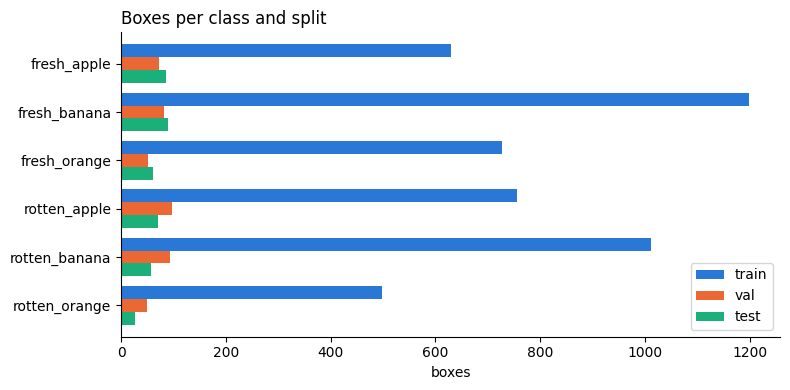

In [6]:
counts = pd.DataFrame(report["boxes"]).reindex(fy.CLASS_NAMES).fillna(0).astype(int)
display(counts)
images = pd.Series(report["images"])
print((images / images.sum() * 100).round(1).astype(str) + " %")

ax = counts.plot.barh(figsize=(8, 4), color=["#2a78d6", "#eb6834", "#1baf7a"], width=0.8)
ax.invert_yaxis(); ax.set_xlabel("boxes"); ax.set_title("Boxes per class and split", loc="left")
ax.spines[["top", "right"]].set_visible(False)
(fy.output_root() / "figures").mkdir(parents=True, exist_ok=True)
plt.tight_layout(); plt.savefig(fy.output_root() / "figures" / "class_distribution.png", dpi=160); plt.show()

Example images with labels, for the report.

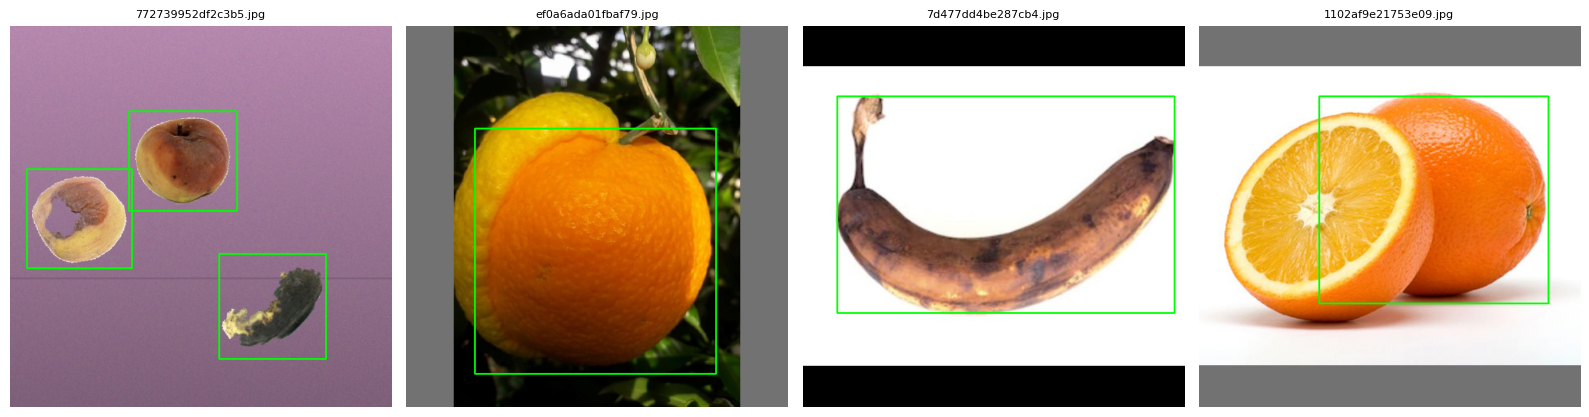

In [7]:
import cv2, random
files = random.Random(0).sample(fy.images_in(fy.DATASET / "images" / "test"), 4)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, path in zip(axes, files):
    image = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]
    for c, x1, y1, x2, y2 in fy.yolo_boxes(fy.DATASET / "labels" / "test" / f"{path.stem}.txt", width, height):
        cv2.rectangle(image, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), max(2, width // 300))
    ax.imshow(image); ax.axis("off"); ax.set_title(path.name, fontsize=8)
plt.tight_layout(); plt.show()

## Hyperparameter tuning

`imgsz`, baseline 640. Each model is evaluated at the size it was trained on. If 800 runs out of GPU memory, tell Daksh.

Only this one value changes. Everything else stays at the shared baseline, so the difference from the baseline can be attributed to it.

In [10]:
assert fy.fetch_dataset(), "Dataset is not on Drive yet."
OWNER = "Jasper"
PARAM, VALUES = fy.TUNING_PLAN[OWNER]
RUNS = [f"{PARAM}_{v}" for v in VALUES]

for name, value in zip(RUNS, VALUES):
    weights = fy.train_run(name, OWNER, overrides={PARAM: value})
    fy.evaluate(name, weights)

Dataset up to date: /content/IAT360-Group-18/datasets/fruit_freshness
GPU: Tesla T4
config.yaml: 6 classes, order matches.
New https://pypi.org/project/ultralytics/8.4.208 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/IAT360-Group-18/config.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou

,owner,changed,accuracy,precision,recall,f1,mAP50,mAP50_95,rotten_recall,rotten_flag_recall,minutes,effective_batch,mAP50_95_vs_baseline
run,,,,,,,,,,,,,
baseline,Daksh,none,0.8661,0.9296,0.9467,0.9381,0.9726,0.8341,0.9257,0.9500,41.1,64,0.0000
imgsz_416,Jasper,imgsz=416,0.8780,0.9373,0.9683,0.9525,0.9734,0.8234,0.9716,0.9667,27.8,64,-0.0107
imgsz_512,Jasper,imgsz=512,0.8632,0.9381,0.9496,0.9438,0.9752,0.8249,0.9349,0.9667,32.5,64,-0.0093
imgsz_800,Jasper,imgsz=800,0.8589,0.9488,0.9263,0.9374,0.9780,0.8212,0.9328,0.9667,58.4,64,-0.0130


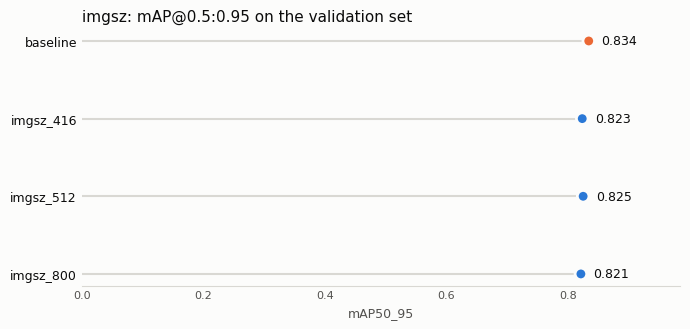

imgsz_416 {'epochs_run': 50, 'best_epoch': 49, 'final_train_loss': 0.6463, 'final_val_loss': 0.9741, 'lowest_val_loss': 0.9676, 'val_loss_rise_after_best': 0.0065, 'train_val_gap': 0.3278, 'reading': 'val loss still falling at the end: likely underfit, train longer'}
imgsz_512 {'epochs_run': 50, 'best_epoch': 50, 'final_train_loss': 0.6368, 'final_val_loss': 0.9599, 'lowest_val_loss': 0.9599, 'val_loss_rise_after_best': 0.0, 'train_val_gap': 0.3231, 'reading': 'val loss still falling at the end: likely underfit, train longer'}
imgsz_800 {'epochs_run': 50, 'best_epoch': 49, 'final_train_loss': 0.6676, 'final_val_loss': 1.0036, 'lowest_val_loss': 0.9887, 'val_loss_rise_after_best': 0.015, 'train_val_gap': 0.336, 'reading': 'val loss still falling at the end: likely underfit, train longer'}


In [11]:
table = fy.compare_runs(names=["baseline"] + RUNS)
display(table)
fy.plot_comparison(table, f"{PARAM}: mAP@0.5:0.95 on the validation set",
                   save_to=fy.output_root() / "figures" / f"tuning_{PARAM}.png")
plt.show()
for name in RUNS:
    print(name, fy.fit_report(name))

In [9]:
from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


### My results

*TODO: which value won, by how much, and why you think that happened. Copy this into the report.*

**Result: none of the image sizes did better than the baseline (640), so we keep 640.**

- 416 and 512 scored about the same as 640. The differences are smaller than 0.0115, which is normal random variation.
- 800 scored a bit worse (−0.013).
- 416 found the most rotten fruit (97% vs 93% for 640) and trained faster (28 min vs 41 min).
- All runs were still improving at 50 epochs, so more training might help.

Make a zip of your runs for GitHub: unzip it at the top of the repo and commit.

In [13]:
fy.package_results(RUNS)

Unzip at the top of the repo, then commit: /content/drive/MyDrive/IAT360-Group 18/results/results_for_github.zip


'/content/drive/MyDrive/IAT360-Group 18/results/results_for_github.zip'

In [14]:
from google.colab import files
files.download("/content/drive/MyDrive/IAT360-Group 18/results/results_for_github.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Bonus: augmentation

YOLO's default `hsv_s=0.7` shifts saturation heavily, and colour is the main sign of rot, so the proposal asked for limited
colour jitter. Three conditions: no augmentation, limited, and the baseline's defaults.

In [15]:
NO_AUGMENT = dict(hsv_h=0, hsv_s=0, hsv_v=0, fliplr=0, scale=0, translate=0, mosaic=0)
LIMITED = dict(hsv_h=0.005, hsv_s=0.2, hsv_v=0.2, fliplr=0.5, scale=0.5)

for name, overrides in {"aug_none": NO_AUGMENT, "aug_limited": LIMITED}.items():
    weights = fy.train_run(name, "Jasper", overrides=overrides)
    fy.evaluate(name, weights)
display(fy.compare_runs(names=["baseline", "aug_none", "aug_limited"]))

GPU: Tesla T4
config.yaml: 6 classes, order matches.
New https://pypi.org/project/ultralytics/8.4.208 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/IAT360-Group-18/config.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300,

,owner,changed,accuracy,precision,recall,f1,mAP50,mAP50_95,rotten_recall,rotten_flag_recall,minutes,effective_batch,mAP50_95_vs_baseline
run,,,,,,,,,,,,,
aug_limited,Jasper,"hsv_h=0.005, hsv_s=0.2, hsv_v=0.2, fliplr=0.5,...",0.8905,0.9508,0.9440,0.9474,0.9770,0.8243,0.9473,0.9667,39.7,64,-0.0098
aug_none,Jasper,"hsv_h=0, hsv_s=0, hsv_v=0, fliplr=0, scale=0, ...",0.8320,0.8933,0.9224,0.9076,0.9504,0.7667,0.8727,0.9167,34.3,64,-0.0674
baseline,Daksh,none,0.8661,0.9296,0.9467,0.9381,0.9726,0.8341,0.9257,0.9500,41.1,64,0.0000


### My results

*TODO: did limited colour jitter help the rotten classes in particular?*

**Result: softer colour changes scored about the same as the baseline but found more rotten fruit. No augmentation was clearly worse.**


- Softer colour: about the same score (the difference is smaller than 0.0115), but it found more rotten fruit (95% vs 93%).
- No augmentation: worse on every score, and especially bad on rotten bananas (0.54 vs 0.67 with softer colour).
- So yes, softer colour changes helped the rotten fruit a little.

In [16]:
fy.package_results(["imgsz_416", "imgsz_512", "imgsz_800", "aug_none", "aug_limited"])
from google.colab import files
files.download("/content/drive/MyDrive/IAT360-Group 18/results/results_for_github.zip")

Unzip at the top of the repo, then commit: /content/drive/MyDrive/IAT360-Group 18/results/results_for_github.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>